#Libraries

In [1]:
import re
import numpy as np
from xml.dom import minidom
import cv2
import matplotlib.pyplot as plt
!pip install git+https://github.com/wannesm/dtaidistance.git#egg=dtaidistance
from dtaidistance import dtw
from dtaidistance import dtw_ndim
from dtaidistance import dtw_visualisation as dtwvis

#Parameters
with_r and height_r for resizing images and default value is 100 pixels

train_set and validation_set is the set of pages that are used in training and validation respectively

D is the set of threshold (distances) that we have tested

In [2]:
width_r=100
height_r=100

train_set = [270, 271, 272]#, 273, 274, 275, 276, 277, 278, 279]
valid_set = [300]#,301,302,303,304]

D=[15,14,13,12,11,10,9,8,7,6,5,4,3,]

#Features

The follwing 6 fitures are used:


1.   Lower contour
2.   Upper contour
3.   Transition from balck pixel to white
4.   Fraction of total balck pixels in the window
5.   Fraction of black pixels between LC and UC
6.   Gradient of feature 5



In [3]:
def count_none_zero(img):
  nozero = img[img > 0]
  return len(nozero)

In [4]:
# Lower contour
def feature1(img, height):
  LC = 0
  for pixel in img:
    #increase lower conture until you see a black pixel
    LC+=1
    if(pixel == 0):
      break;
  if(LC <0 or LC > height):
    print("eror occured")
  return LC

In [5]:
# Upper contour
def feature2(img, height):
  UC = height
  for pixel in img:
    #decrease the upperbound conture until you see a black pixel
    UC-=1
    if(pixel == 0):
      break;
  if(UC <0 or UC > height):
    print("eror occured")
  return UC

In [6]:
# Transitions from black pixels to white
def feature3(img,height):
  
  transitions=0
  seen_white = True

  for pixel in img:
    if(pixel == 0 and seen_white == True):
      seen_white = False
      transitions += 1
    elif(pixel !=0 and seen_white == False):
      seen_white = True
      transitions += 1
  return transitions

In [7]:
#Fraction of black pixels in the window
def feature4(img,height):
  
  return (1*height - count_none_zero(img))/(1*height)*100

In [8]:
#Fraction of black pixels between LC and UC
def feature5(img,height):
  UC= height
  LC = 0
  for pixel in img:
    LC+=1
    if(pixel == 0):
      break;
  for pixel in reversed(img):
    UC-=1
    if(pixel == 0):
      break;
  if(LC<UC):  
    cropped_img = img[LC:UC,:]
    total_pixels = 1*(UC-LC) 
  else:
    cropped_img = img
    total_pixels = 1*height
    
  return ((total_pixels - count_none_zero(cropped_img))/total_pixels)*100

In [9]:
#Gradient of fraction of black pixels in two consequent windows
def feature6(img_prev,img_cur,height):
  return (feature2(img_cur,height)-feature2(img_prev,height))

#Normalization

We normalize the feature vectors using their mean and standard deviation

In [10]:
def normalization(input_list,epsilon=1e-100):
  return (np.array(input_list)-np.array(input_list).mean())/(np.array(input_list).std()+epsilon)

#Sliding window

On each image, and sliding widow of width=1 and offset=1 will move and we will calculate the features on each window and store them in feature vector list

In [11]:
def slidign_window(img_width, img_height, window_width, offset, img):
  
  feature1_list = []
  feature2_list = []
  feature3_list = []
  feature4_list = []
  feature5_list = []
  feature6_list = []

  for w in range(int(img_width/offset)-1):
  
    if(w!=0):
      window_prev = img[:,(w-1)*offset:(w-1)*offset+window_width]


    window_cur = img[:,w*offset:w*offset+window_width]
     
    feature1_list.append(feature1(window_cur,img_height))
    feature2_list.append(feature2(window_cur,img_height))
    feature3_list.append(feature3(window_cur,img_height)) 
    feature4_list.append(feature4(window_cur,img_height))
    feature5_list.append(feature5(window_cur,img_height))
    if(w!=0):
      feature6_list.append(feature6(window_prev,window_cur,img_height))
    else:
      feature6_list.append(0)
  return normalization(feature1_list,0), normalization(feature2_list,0), normalization(feature3_list,0), normalization(feature4_list,0), normalization(feature5_list,0), normalization(feature6_list,0)

In [12]:
def Polygon_Coordinates(svg_path):
  poly = minidom.parse(svg_path)
  all_path = poly.getElementsByTagName('path')

  x_coor_all = []
  y_coor_all = []
  for path in all_path:
    string_path = path.getAttribute('d')             #Each Polygon path
    string_coor = re.findall('[0-9]*\.[0-9]*', string_path)    #Each Polygon Coordinates(String)
    x_coor = []
    y_coor = []
    for i in range(len(string_coor)):
      if (i%2==0):
        x_coor.append(float(string_coor[i]))         #Each Polygon X_Coordinates
      else:
        y_coor.append(float(string_coor[i]))         #Each Polygon Y_Coordinates
  
    x_coor_all.append(x_coor)                        # All Polygons X_Coordinates
    y_coor_all.append(y_coor)                        # All Polygons Y_Coordinates
  
  return x_coor_all , y_coor_all

In [13]:
def Polygon_Image(image_path, x, y):
  # Polygon Coordinates
  points=np.concatenate((np.array([x]), np.array([y]))).T
  corners = np.array([points], dtype=np.int32)

  image = cv2.imread(image_path,0)
  # mask defaulting to black for 3-channel
  mask = np.ones_like(image, np.uint8)*255

  # fill the Polygon so it doesn't get wiped out when the mask is applied
  channel_count = 1#image.shape[2] 
  ignore_mask_color = (0,)*channel_count
  cv2.fillPoly(mask, corners, ignore_mask_color)

  # apply the mask
  masked_image = cv2.bitwise_or(image, mask)

  # Crop 
  rect = cv2.boundingRect(corners) # Returns (x_0,y_0,W,H) of the Rectangular
  cropped = masked_image[rect[1]: rect[1] + rect[3], rect[0]: rect[0] + rect[2]]
  return cropped

#Processing ground truth
By reading the "transcription.txt" file generates a 2D list where the first dimenstion is 14 (pages) and the second dimension is the list of words in that specific page

In [14]:
import csv
import numpy as np
pages = [270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 300, 301, 302, 303, 304]

def process_gt(file_name):

  temp = []
  keyword = []
  page_list = []

  reader = csv.reader(open(file_name), delimiter=" ")

  for row in reader:

    temp.append(row[0].split('-'))
    keyword.append(row[1])

  for idx_p in range(len(pages)):

    page_list.append([])

    for idx_t in range(len(temp)):

      if(pages[idx_p] == int(temp[idx_t][0])):
        
        page_list[idx_p].append(keyword[idx_t])

    
  return page_list

#calculating the recall and precision

Receives as input the list of the top-k matches of the validation set and using the ground truch calculates the recall and precison

In [15]:
def cal_recall_precision(neighbours):
  
  per_page_word_list = process_gt("transcription.txt")
  TP_full = 0.0
  FP_full = 0.0
  FN_full = 0.0

  precision = 0.0
  recall = 0.0

  for n in neighbours:

    if(len(n)>0):
      TP = 0.0
      FN = 0.0
      FP = 0.0
      for sq_v,sq_t in n:
        # print(per_page_word_list[sq_v[0]][sq_v[1]])
        # print(per_page_word_list[sq_t[0]][sq_t[1]])
        if(per_page_word_list[sq_v[0]][sq_v[1]] == per_page_word_list[sq_t[0]][sq_t[1]]):
          TP +=1
        else:
          FP +=1
        
        for pg_idx in range(len(pages)):
          for w in per_page_word_list[pg_idx]:
            if(w == per_page_word_list [sq_v[0]][sq_v[1]]):
             FN += 1
        FN -= TP
      # print("TP is:{:f}".format(TP))
      # print("FP is:{:f}".format(FP))
      # print("FN is:{:f}".format(FN))
      TP_full +=TP
      FP_full += FP
      FN_full += FN
      precision = (TP_full)/(TP_full + FP_full)
      recall = (TP_full)/(TP_full + FN_full)
  
  return precision, recall

#Drawing a sample pf DTW output

Here we show an example of who our features look like and what is the DTW solution for the first two words of page 270

1ST Feature DTW
21.87932813938192


(<Figure size 720x720 with 4 Axes>,
  <matplotlib.axes._subplots.AxesSubplot at 0x7fe58051d690>])

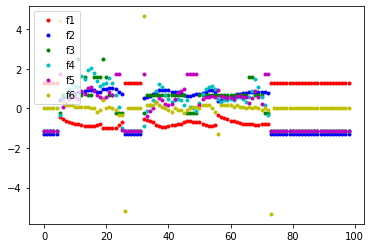

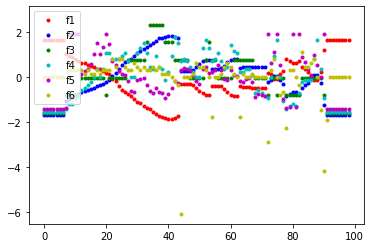

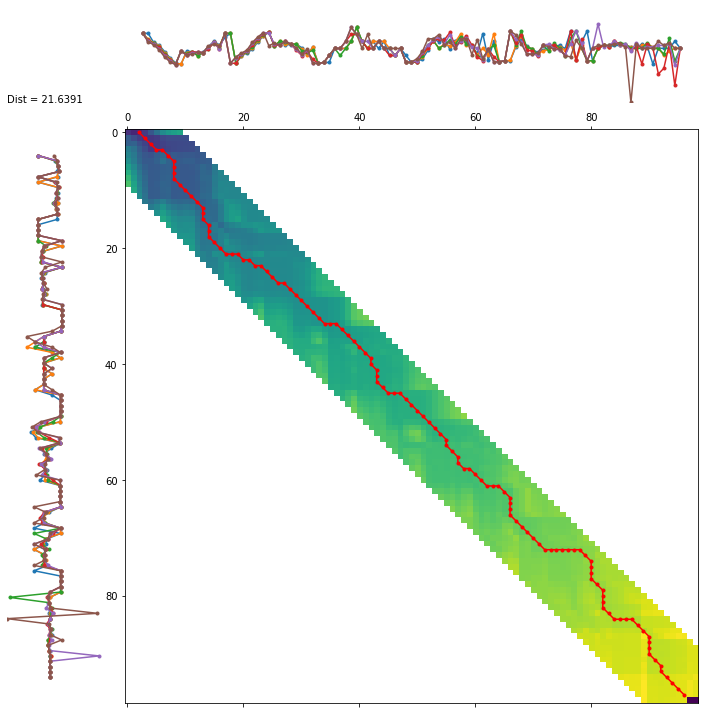

In [16]:
import warnings
warnings.filterwarnings('ignore')


feature_vector_list = []
x_coor_all, y_coor_all = Polygon_Coordinates("270.svg")
for i in range(2):
  each_polygon = Polygon_Image("270.jpg" , x_coor_all[i] , y_coor_all[i]) 
  
  ret,binarized_img = cv2.threshold(each_polygon,127,255,cv2.THRESH_BINARY)
  dsize = (width_r, height_r)
  resized_binarized_img = cv2.resize(binarized_img, dsize)
  
  feature1_list,feature2_list, feature3_list, feature4_list,feature5_list, feature6_list = slidign_window(img_width = width_r, img_height=height_r, window_width=1, offset=1, img=resized_binarized_img)
  
  plt.figure()
  plt.plot(feature1_list,'r.',label="f1")
  plt.plot(feature2_list,'b.',label="f2")
  plt.plot(feature3_list,'g.',label="f3")
  plt.plot(feature4_list,'c.',label="f4")
  plt.plot(feature5_list,'m.',label="f5")
  plt.plot(feature6_list,'y.',label="f6")
  plt.legend(loc="upper left") 

  temp_list = np.concatenate((feature1_list,feature2_list,feature3_list,feature4_list,feature5_list,feature6_list))
  feature_vector = np.reshape(temp_list, (-1,6))
  feature_vector_list.append(feature_vector)
plt.show

print('1ST Feature DTW')
distance, paths = dtw_ndim.warping_paths(feature_vector_list[0], feature_vector_list[1])
print(distance)
#print(paths)
d, paths = dtw_ndim.warping_paths(feature_vector_list[0], feature_vector_list[1], window=10, psi=2)
best_path = dtw.best_path(paths)
dtwvis.plot_warpingpaths(feature_vector_list[0], feature_vector_list[1], paths, best_path)



#Find feature vectors in the train dataset

In [17]:
train_feature_vector_list=[]
train_sequence = []

for pg_idx in range(len(train_set)):

  train_image_path = str(train_set[pg_idx]) + ".jpg"
  train_svg_path = str(train_set[pg_idx]) + ".svg"
  train_x_coor_all, train_y_coor_all = Polygon_Coordinates(train_svg_path)

  for iter in range(len(train_x_coor_all)):

    train_each_polygon = Polygon_Image(train_image_path , train_x_coor_all[iter] , train_y_coor_all[iter]) 

    ret,train_binarized_img = cv2.threshold(train_each_polygon,127,255,cv2.THRESH_BINARY)
    dsize = (width_r, height_r)
    train_resized_binarized_img = cv2.resize(train_binarized_img, dsize)

    train_feature1_list,train_feature2_list, train_feature3_list, train_feature4_list,train_feature5_list, train_feature6_list = slidign_window(img_width = width_r, img_height=height_r, window_width=1, offset=10, img=train_resized_binarized_img)
    train_temp_list = np.concatenate((train_feature1_list,train_feature2_list,train_feature3_list,train_feature4_list,train_feature5_list,train_feature6_list))
    train_feature_vector = np.reshape(train_temp_list, (-1,6))
    train_feature_vector_list.append(train_feature_vector)
    train_sequence.append((pg_idx,iter))


#Find feature vectors in the validation dataset

In [18]:
valid_feature_vector_list=[]
valid_sequence = []

for pg_idx in range(len(valid_set)):

  valid_image_path = str(valid_set[pg_idx]) + ".jpg"
  valid_svg_path = str(valid_set[pg_idx]) + ".svg"

  valid_x_coor_all, valid_y_coor_all = Polygon_Coordinates(valid_svg_path)

  for iter in range(len(valid_x_coor_all)):

    valid_each_polygon = Polygon_Image(valid_image_path , valid_x_coor_all[iter] , valid_y_coor_all[iter]) 
    
    ret,valid_binarized_img = cv2.threshold(valid_each_polygon,127,255,cv2.THRESH_BINARY)
    dsize = (width_r, height_r)
    valid_resized_binarized_img = cv2.resize(valid_binarized_img, dsize)
    
    valid_feature1_list,valid_feature2_list, valid_feature3_list, valid_feature4_list,valid_feature5_list, valid_feature6_list = slidign_window(img_width = width_r, img_height=height_r, window_width=1, offset=10, img=valid_resized_binarized_img)
    
    valid_temp_list = np.concatenate((valid_feature1_list,valid_feature2_list,valid_feature3_list,valid_feature4_list,valid_feature5_list,valid_feature6_list))
    valid_feature_vector = np.reshape(valid_temp_list, (-1,6))
    
    valid_feature_vector_list.append(valid_feature_vector)
    #because validation pages start from 300
    valid_sequence.append((pg_idx + 9,iter))

#Draw recall and precision

In [19]:
recall_list = []
precision_list = []

for d in D:

  neighbours = []
  
  for idx_v in range( len(valid_feature_vector_list)): #NOTE: REMOVE 200
    
    neighbours.append([])
    
    for idx_t in range(len(train_feature_vector_list)): #NOTE REMOVE 200
      
      
      distance, paths = dtw_ndim.warping_paths(valid_feature_vector_list[idx_v], train_feature_vector_list[idx_t])
      #print("dist is:{:f}".format(distance))
      if(distance < d):
        neighbours[idx_v].append((valid_sequence[idx_v],train_sequence[idx_t]))
    
  precision, recall = cal_recall_precision(neighbours)
  recall_list.append(recall)
  precision_list.append(precision)


[0.01011706128502569, 0.01011706128502569, 0.01011706128502569, 0.010121015015930001, 0.010183052491211056, 0.010161633978256288, 0.010817728518478275, 0.012089765872610162, 0.013315001085462045, 0.01514386673397274, 0.01929260450160772, 0.021052631578947368, 0.0]
[0.0002952676974626882, 0.0002952676974626882, 0.0002952676974626882, 0.0002954433661363123, 0.00029651151845274326, 0.00029071351188174257, 0.0003010969202758532, 0.00033458868934607363, 0.0003792250618301731, 0.00046104549750651227, 0.0005878126836914636, 0.0005111821086261981, 0.0]


Text(0.5, 0, 'recall')

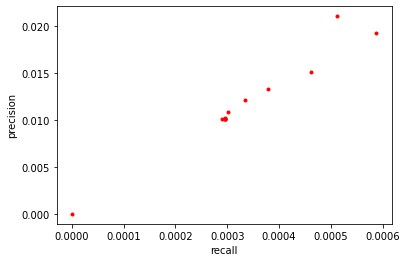

In [20]:
print(precision_list)
print(recall_list)
plt.plot(recall_list,precision_list,'r.')
plt.ylabel("precision")
plt.xlabel("recall")